# Scripting with `codecal`

Everything the interface does is a few function calls. This page is the
tour of the package: build a model, evaluate a design situation, run the
sweep, calibrate, verify, plot, and feed a modified model back in. The
{doc}`../reference/api` lists every function.

In [1]:
import os
import sys

import numpy as np
import pandas as pd

try:
    import codecal as cc
except ImportError:
    sys.path.insert(0, os.path.abspath('../..'))
    import codecal as cc
from codecal import plots

pd.set_option('display.width', 140)

## The model

`ahg_spec()` is the AHG model as a plain dictionary; `build_model`
turns it into a `CalibrationModel` (simulating the characteristic
loads on the way). `ahg_model()` does both. One million draws are
enough for a script; the tests use ten million.

In [2]:
spec = cc.ahg_spec(n_mcs=1_000_000)
model = cc.build_model(spec)
print(model.summary()[:600], '...')

AHG 2021 — Reliability Background of the Eurocodes

reference period 50 a, target β 3.8
9 failure modes × 3 loads × 3 a_G × 10 a_Q = 810 design situations

Failure modes:
  Steel bending: Θ_R mean 1.15 CoV 0.05, R CoV 0.050 (x_k 0.830), γ_M 1.0, a_Q (0.3, 0.8), a_G (0.6, 1.0), w 0.17
  Concrete compression: Θ_R mean 0.97 CoV 0.14, R CoV 0.100 (x_k 0.844), γ_M 1.5, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.12
  Concrete bending: Θ_R mean 1.03 CoV 0.07, R CoV 0.045 (x_k 0.928), γ_M 1.15, a_Q (0.1, 0.7), a_G (0.6, 1.0), w 0.4
  Glulam bending: Θ_R mean 1.00 CoV 0.10, R CoV 0.150 (x_k 0.774), γ_M 1.25,  ...


The model is a list of failure modes and a list of variable loads; each
carries its random variables. A `RandomVariable` knows its
distribution, its characteristic value and how to map a standard-normal
`u` to `x`.

In [3]:
steel = model.failure_modes[0]
print(steel.name, '—', steel.R.name, type(steel.R.dist).__name__, 'CoV', round(steel.R.cov, 3), 'x_k', steel.R.char)
wind = model.loads[0]
print(wind.name, '— Q at the analysis period: mean', round(wind.Q.mean, 3), 'CoV', wind.Q.cov, 'q_k', round(wind.Q.char, 3))
print('x(u) for u = -2, 0, 2:', np.round(steel.R.dist.x_of_u(np.array([-2.0, 0.0, 2.0])), 3))

Steel bending — Steel yield strength Lognormal CoV 0.05 x_k 0.83
wind — Q at the analysis period: mean 1.0 CoV 0.14 q_k 1.084
x(u) for u = -2, 0, 2: [0.904 0.999 1.104]


## One design situation

A `DesignSituation` is a failure mode, a load and the proportions
$(a_G, a_Q)$. `design_parameter` applies the design equation,
`limit_state` builds $g$, and `reliability` does both and runs FORM.

In [4]:
pf = cc.PartialFactors(gamma_G=1.35, gamma_GP=1.35, gamma_Q={'wind': 1.5, 'snow': 1.5, 'imposed': 1.5}, xi=0.85)
sit = cc.DesignSituation(steel, wind, a_G=0.8, a_Q=0.5, weight=1.0, model=model)
for eq in ('8.12', '8.13', '8.14'):
    beta, res, z = sit.reliability(pf, equation=eq)
    print(f'eq. {eq}: z = {z:.4f}, β = {beta:.3f}, converged in {res.iterations} iterations')
print('sensitivities α²:', res.sensitivities(sit.variable_names))

eq. 8.12: z = 1.7924, β = 3.573, converged in 11 iterations
eq. 8.13: z = 1.6704, β = 3.292, converged in 11 iterations
eq. 8.14: z = 1.6704, β = 3.292, converged in 11 iterations
sensitivities α²: {'Θ_R': 0.0408, 'R': 0.0408, 'Θ_E': 0.1625, 'G': 0.0007, 'P': 0.0007, 'Θ_Q': 0.4972, 'Q': 0.2574}


## The sweep

`evaluate` runs FORM (or SORM) for every design situation and returns
one row per situation. `weighted_mean_beta` and `beta_table` summarise
it; the plot functions draw it.

In [5]:
df = cc.evaluate(model, pf, equation='8.12')
print(len(df), 'situations; weighted-mean β =', round(cc.weighted_mean_beta(df), 3),
      '; objective M =', round(cc.objective(df, 3.8), 4))
df.head()

810 situations; weighted-mean β = 3.742 ; objective M = 0.1888


,mode,load,a_G,a_Q,weight,z,beta,form_iterations,converged,alpha_Θ_R,alpha_R,alpha_Θ_E,alpha_G,alpha_P,alpha_Θ_Q,alpha_Q
0,Steel bending,wind,0.6,0.300000,0.002269,1.726060,4.194377,14,True,-0.241254,-0.241254,0.481608,0.034480,0.091946,0.636583,0.486586
1,Steel bending,wind,0.6,0.355556,0.002269,1.744496,3.986871,13,True,-0.224728,-0.224728,0.448618,0.028259,0.075358,0.661800,0.503269
2,Steel bending,wind,0.6,0.411111,0.002269,1.762932,3.808279,12,True,-0.211986,-0.211986,0.423182,0.023474,0.062596,0.680436,0.513399
3,Steel bending,wind,0.6,0.466667,0.002269,1.781368,3.653423,12,True,-0.201657,-0.201657,0.402563,0.019596,0.052256,0.695126,0.519901
4,Steel bending,wind,0.6,0.522222,0.002269,1.799804,3.517940,11,True,-0.192991,-0.192991,0.385263,0.016343,0.043582,0.707192,0.524208


In [6]:
cc.beta_table(df).round(2)

load,wind,snow,imposed
mode,,,
Steel bending,3.52,3.17,3.94
Concrete compression,3.84,3.62,4.15
Concrete bending,3.42,3.15,3.78
Glulam bending,3.34,3.08,3.71
Timber bending,3.41,3.17,3.74
Masonry,4.10,3.92,4.37
Aluminium bending,3.61,3.31,4.00
Pile foundation,3.55,3.42,3.79
Shallow foundation,3.73,3.59,3.98


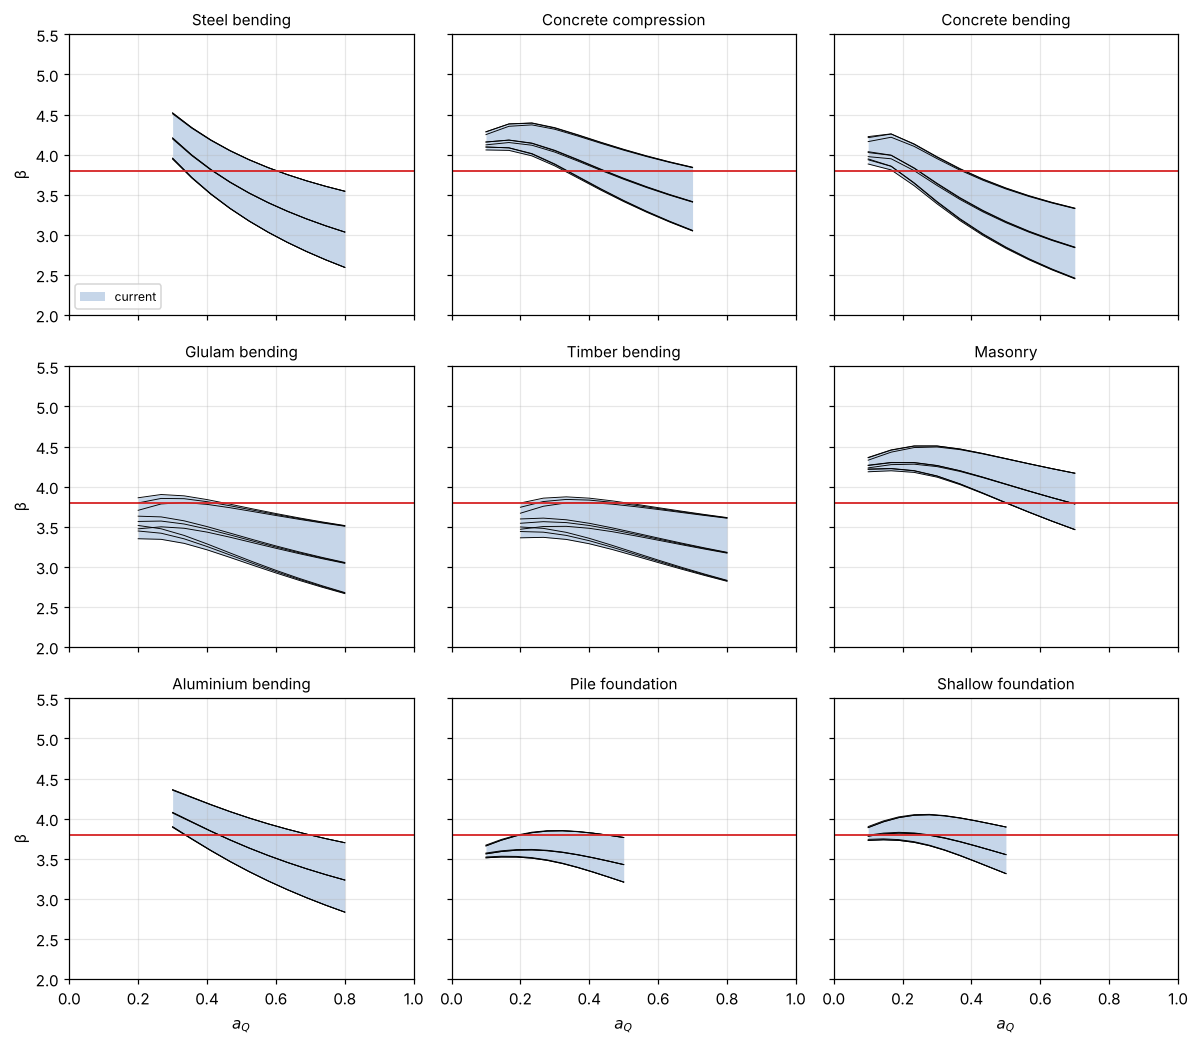

In [7]:
plots.plot_beta_vs_aQ(df, 3.8)

## Calibration

`calibrate` minimises $M(\gamma)$ over the named parameters. Names:
`gamma_G`, `gamma_GP`, `gamma_Q` (common), `gamma_Q:<load>` (per load),
`xi`. Setting `gamma_G` without `gamma_GP` sets both permanent-load
factors (the convention of the study).

In [8]:
res = cc.calibrate(model, free=('gamma_G', 'gamma_Q'), start=pf, equation='8.12', beta_target=3.8, verbose=False)
print(res)

calibrated gamma_G, gamma_Q  (β_t = 3.8)
  gamma_G            1.215
  gamma_Q            1.750
  weighted-mean β  3.742 → 3.809
  objective        1.365e-01   (16 evaluations)


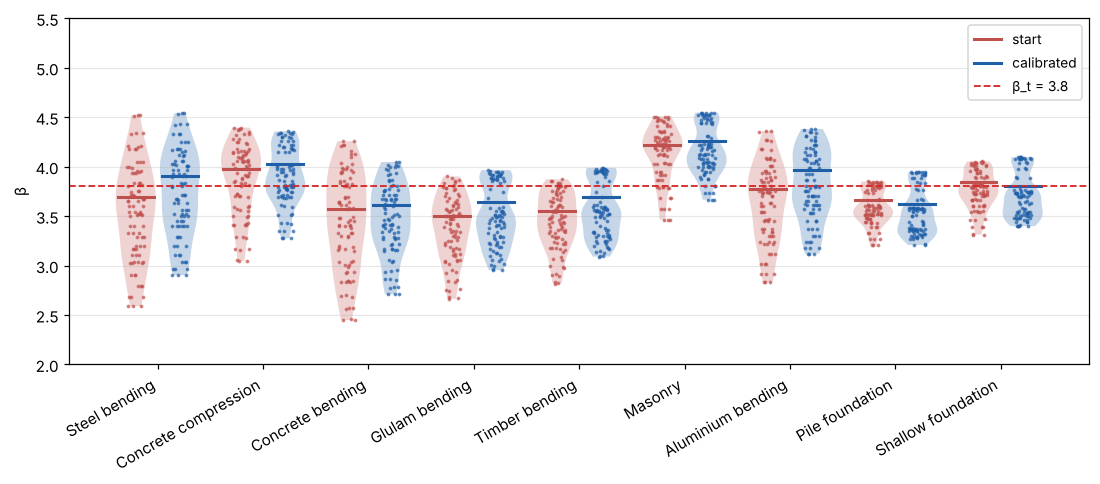

In [9]:
plots.plot_beta_distribution(res.sweep_after, 'mode', 3.8, ref_df=res.sweep_before, labels=('calibrated', 'start'))

`CalibrationResult` carries the factors, the sweeps before and after,
the optimiser history and the scipy result:

In [10]:
print(res.factors)
print('evaluations:', len(res.history), '| SLSQP:', res.optimizer.message)
print('γ_Q,wind of the result:', res.factors.get('gamma_Q:wind'))

PartialFactors(gamma_G=1.2154096497373543, gamma_GP=1.2154096497373543, gamma_Q={'wind': 1.75032560483013, 'snow': 1.75032560483013, 'imposed': 1.75032560483013}, xi=0.85)
evaluations: 16 | SLSQP: Optimization terminated successfully
γ_Q,wind of the result: 1.75032560483013


## Verification of one situation

`form`, `sorm`, `importance_sampling` and `monte_carlo` work on any
`LimitState` — the ones of the model, or your own.

In [11]:
z = sit.design_parameter(res.factors, '8.12')
ls = sit.limit_state(z)
r = cc.form(ls)
b_sorm, kappa = cc.sorm(ls, r)
isr = cc.importance_sampling(ls, r, n=50_000, seed=1)
print(f'FORM {r.beta:.4f}   SORM {b_sorm:.4f}   IS {isr.beta:.4f} ± {isr.se_beta:.4f}')

FORM 3.7472   SORM 3.7072   IS 3.7075 ± 0.0024


A limit state of your own: two variables, $g = R - S$.

β = 2.792, α = [-0.42   0.908], design point x* = [2.076 2.076]


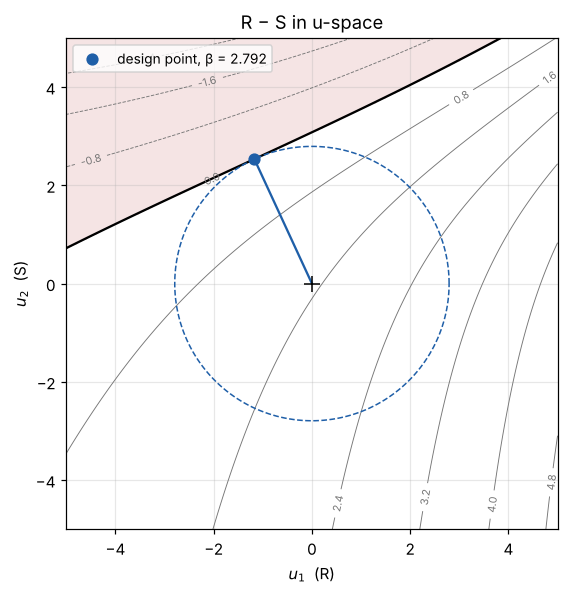

In [12]:
R = cc.rv('R', 'lognormal', mean=2.5, cov=0.15, fractile=0.05)
S = cc.rv('S', 'gumbel', mean=1.0, cov=0.30, fractile=0.98)
ls2 = cc.LimitState(lambda x: x[0] - x[1], [R, S], name='R − S')
r2 = cc.form(ls2)
print(f'β = {r2.beta:.3f}, α = {np.round(r2.alpha, 3)}, design point x* = {np.round(r2.x_star, 3)}')
plots.plot_limit_state_2d(ls2, r2, title='R − S in u-space')

## A modified model

Edit the dictionary, validate, build, and compare — the same thing the
lab mode does. Here: snow with a more uncertain model (CoV 0.26 → 0.35).

In [13]:
spec2 = cc.ahg_spec(n_mcs=1_000_000)
spec2['loads'][1]['theta_Q']['cov'] = 0.35
print('problems:', cc.validate_spec(spec2))
print('changes:', cc.diff_specs(spec, spec2))
model2 = cc.build_model(spec2)
df2 = cc.evaluate(model2, pf, equation='8.12')
print('weighted-mean β:', round(cc.weighted_mean_beta(df), 3), '→', round(cc.weighted_mean_beta(df2), 3))
cc.beta_table(df2).round(2)['snow'].to_frame('snow, CoV(Θ_Q) = 0.35').join(cc.beta_table(df).round(2)['snow'].to_frame('snow, CoV(Θ_Q) = 0.26'))

problems: []
changes: [('loads[snow].theta_Q.cov', 0.26, 0.35)]


weighted-mean β: 3.742 → 3.727


,"snow, CoV(Θ_Q) = 0.35","snow, CoV(Θ_Q) = 0.26"
mode,,
Steel bending,2.93,3.17
Concrete compression,3.49,3.62
Concrete bending,3.00,3.15
Glulam bending,2.98,3.08
Timber bending,3.09,3.17
Masonry,3.82,3.92
Aluminium bending,3.13,3.31
Pile foundation,3.38,3.42
Shallow foundation,3.53,3.59


Save it for the lab mode, or for the command line
(`python run_calibration.py --model snow_035.json`):

In [14]:
with open('snow_035.json', 'w', encoding='utf-8') as f:
    f.write(cc.to_json(spec2))
print(open('snow_035.json').read()[:300], '...')
os.remove('snow_035.json')

{
 "name": "AHG 2021 — Reliability Background of the Eurocodes",
 "T_ref": 50,
 "n_aQ": 10,
 "n_aG": 3,
 "beta_target": 3.8,
 "seed": 12345,
 "n_mcs": 1000000,
 "theta_E": {
  "name": "Load-effect model uncertainty",
  "family": "lognormal",
  "mean": 1.0,
  "cov": 0.1,
  "char": 1.0,
  "note": "by  ...
